<h1 align="center">Dynamic Routing</h1>  
<h1 align="center">Allen Institute/Neural Dynamics</h1>  
    

**Goal:** This tutorial will cover data access, details of the experiment, exploration and scientific analysis.

  We will:
  1. Find & load data packaged as NWB files
  2. Explain the design of the Dynamic Routing task
  3. Visualize task performance
  4. Summarize the brain areas recorded
  5. Explore data around stimulus onset: neural activity, running speed, face motion

For general information about the Dynamic Routing project, see [README.md](../README.md)

In [ ]:
# also need to figure out some issues with the pynwb utils 
# not sure if it's totally necessary 

# final tutorial will show remote access 

# also need to identify a good example unit 


In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2 

In [2]:
import pathlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

warnings.filterwarnings('ignore', module='hdmf_zarr') # known issues, can be ignored

pd.options.display.max_colwidth = None # see long strings in dataframe preview

BOOL_COLORS = {False: "#aec7e8", True: "#1f77b4"} # shared colors for boolean columns


---

## NWB files
### Inventory

In [3]:
metadata = pd.read_csv('/data/metadata/dynamic_routing_metadata.csv')
metadata.head()

,project_name,_id,name,subject_id,genotype,date_of_birth,age,sex,modality,session_date,session_start_time,session_end_time,targeted_structure,trials_total,trials_rewarded,reward_rate,reward_consumed_mL,mean_dprime_same_modal,mean_dprime_other_modal
0,Dynamic Routing,897335f6-895c-455e-89c4-667d86a4304e,ecephys_662892_2023-08-24_14-28-28_nwb_2026-08-04_15-13-29,662892,Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,2022-12-24,243,Female,"['Extracellular electrophysiology', 'Behavior', 'Behavior videos']",2023-08-24,2023-08-24T14:28:28-07:00,2023-08-24T16:28:14.588745Z,['Piriform area' 'root'],476,123,0.258403,3.84,2.152875,2.209537
1,Dynamic Routing,c4ec72da-c795-4da8-a498-3531a621ddc0,ecephys_664851_2023-11-16_12-54-53_nwb_2026-08-04_15-09-33,664851,Pvalb-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,2023-01-09,311,Female,"['Extracellular electrophysiology', 'Behavior', 'Behavior videos']",2023-11-16,2023-11-16T12:54:53-08:00,2023-11-16T14:46:25.481437Z,"['Secondary motor area' 'Field CA1' 'Subiculum' 'Prelimbic area'\n 'Orbital area, medial part']",527,139,0.263757,4.35,3.133879,2.593231
2,Dynamic Routing,678d3a97-d1f2-4533-a7e0-1300fed47cfb,ecephys_667252_2023-09-28_15-00-38_nwb_2026-08-04_15-21-37,667252,wt/wt,2023-01-27,244,Female,"['Extracellular electrophysiology', 'Behavior', 'Behavior videos']",2023-09-28,2023-09-28T15:00:38-07:00,2023-09-28T17:03:03.333877Z,['Secondary motor area' 'Primary motor area' 'Prosubiculum'\n 'Secondary motor area'],486,123,0.253086,3.78,3.261005,2.260717
3,Dynamic Routing,ffa07448-b91d-4bdf-b3ab-9e6f2c5a8b4d,ecephys_708016_2024-04-29_12-59-12_nwb_2026-08-04_15-02-46,708016,Vip-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,2023-10-18,194,Male,"['Extracellular electrophysiology', 'Behavior', 'Behavior videos']",2024-04-29,2024-04-29T12:59:12-07:00,2024-04-29T15:00:31.755703Z,"['Secondary motor area' 'Primary somatosensory area' 'Field CA3'\n 'Medial geniculate complex, ventral part']",533,129,0.242026,4.05,3.027970,2.665116
4,Dynamic Routing,9deb4162-9e9b-4ee7-b5e4-db804fd4fcd5,ecephys_712815_2024-05-22_12-26-32_nwb_2026-08-04_14-59-22,712815,wt/wt,2023-11-17,187,Female,"['Extracellular electrophysiology', 'Behavior', 'Behavior videos']",2024-05-22,2024-05-22T12:26:32-07:00,2024-05-22T14:23:25.111009Z,['Dentate gyrus' 'Posterior complex of the thalamus' 'Field CA1'\n 'Primary somatosensory area' 'Primary somatosensory area' 'Caudoputamen'],545,138,0.253211,4.17,2.988601,1.745163


> 💡 
> 
> `/root/capsule/data` is equivalent to the `data` directory we see.


### Opening an NWB file
<img src="images/nwb-file.png" style="max-width: 400px; height: auto;">

Read one NWB file using `pynwb`:

In [4]:
import pynwb 

selected_path = '/root/capsule/data/dynamicrouting_datacube/ecephys_742903_2024-10-23_14-12-23_nwb_2026-08-04_15-14-57/742903_2024-10-23.nwb.zarr' 

nwb = pynwb.read_nwb(selected_path)

print(type(nwb))

<class 'pynwb.file.NWBFile'>


Instantiating the `NWBFile` object (**above**) is mostly lazy and reasonably fast.

Displaying the object in a notebook (**below**) eagerly loads all tables, so it can take much longer!

In [5]:
nwb

UnsafeDecodeError: Pickle.decode is disabled because unpickling data can execute arbitrary code. If you trust the source of this data, enable it by setting numcodecs.pickles.ALLOW_UNSAFE_PICKLE_DECODE = True, or by setting the environment variable NUMCODECS_ALLOW_UNSAFE_PICKLE_DECODE=1 before importing numcodecs.

root pynwb.file.NWBFile at 0x140054780470928
Fields:
  acquisition: {
    frametimes_eye_camera <class 'hdmf.common.table.DynamicTable'>,
    frametimes_front_camera <class 'hdmf.common.table.DynamicTable'>,
    frametimes_side_camera <class 'hdmf.common.table.DynamicTable'>,
    manipulator_positions <class 'hdmf.common.table.DynamicTable'>
  }
  devices: {
    17131307152 <class 'pynwb.device.Device'>,
    18005120322 <class 'pynwb.device.Device'>,
    20097906812 <class 'pynwb.device.Device'>,
    20097906862 <class 'pynwb.device.Device'>,
    22175718152 <class 'pynwb.device.Device'>,
    SN40902 <class 'pynwb.device.Device'>,
    SN40903 <class 'pynwb.device.Device'>,
    SN40906 <class 'pynwb.device.Device'>,
    SN40907 <class 'pynwb.device.Device'>,
    SN40908 <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    probeA <class 'pynwb.ecephys.ElectrodeGroup'>,
    probeB <class 'pynwb.ecephys.ElectrodeGroup'>,
    probeC <class 'pynwb.ecephys.ElectrodeGroup'>,
    probeE 

> **Note:** The interactive widget displayed above will also bloat the static `.html` representation of this notebook — it is advisable to **clear the output** of that cell when finished exploring.

## Epochs within a session

- stored as a table of intervals (i.e. each row has a `start_time` and a `stop_time`)
- column descriptions are included

In [6]:
nwb.intervals["epochs"]

,start_time,stop_time,script_name,notes,interval_names,tags
id,,,,,,
0,50.72719,921.424030,RFMapping,,"[vis_rf_mapping_trials, aud_rf_mapping_trials]",[mapping]
1,931.79804,1108.579450,OptoTagging,,[optotagging_trials],[optotagging]
2,1117.95403,1720.942515,Spontaneous,,[],[spontaneous]
3,1731.38511,2334.489760,SpontaneousRewards,,[],"[rewards, spontaneous]"


Get a dataframe:

In [7]:
epochs = nwb.intervals["epochs"][:]
epochs

,start_time,stop_time,script_name,notes,interval_names,tags
id,,,,,,
0,50.72719,921.424030,RFMapping,,"[vis_rf_mapping_trials, aud_rf_mapping_trials]",[mapping]
1,931.79804,1108.579450,OptoTagging,,[optotagging_trials],[optotagging]
2,1117.95403,1720.942515,Spontaneous,,[],[spontaneous]
3,1731.38511,2334.489760,SpontaneousRewards,,[],"[rewards, spontaneous]"
4,2344.83195,5991.786290,DynamicRouting1,,"[trials, performance]","[task, rewards]"
5,6002.42864,6605.500460,SpontaneousRewards,,[],"[rewards, spontaneous]"
6,6615.75909,7218.880890,Spontaneous,,[],[spontaneous]
7,7229.07277,7405.487130,OptoTagging,,[optotagging_trials],[optotagging]


- `DynamicRouting1` is the behavior task, which lasts about an hour
- other epochs for characterizing neurons or spontaneous behavior 
- some epochs are repeated after the task

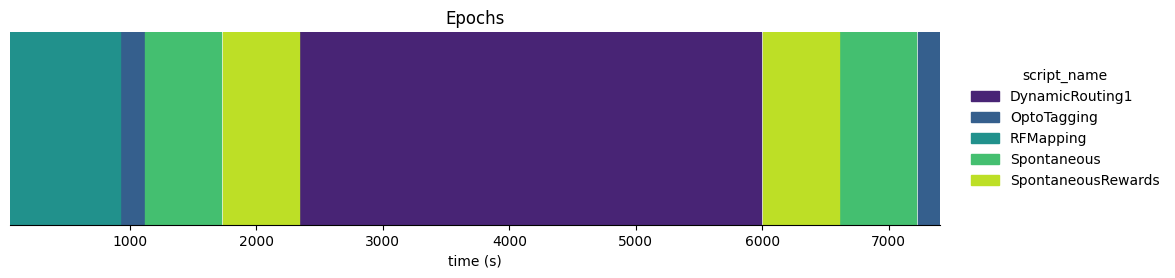

In [22]:
epochs_df = nwb.intervals["epochs"][:]
epochs_df["duration"] = epochs_df["stop_time"] - epochs_df["start_time"]
n = len(epochs_df["script_name"].unique())
colors = plt.cm.viridis(np.linspace(0.1, 0.9, n))   # or "plasma", "cividis", "mako"-style "YlGnBu"

fig, ax = plt.subplots(figsize=(12, 2.5))
for (name, group), color in zip(epochs_df.groupby("script_name"), colors):
    ax.broken_barh(
        list(zip(group["start_time"], group["duration"])),
        (0, 1),
        facecolors=color,
        edgecolor=color,
        label=name,
    )

ax.set(ylim=(0, 1), yticks=[], xlabel="time (s)", title="Epochs")
ax.margins(x=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(title="script_name", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
plt.show()

In [19]:
names = epochs.script_name.unique()
colors = dict(zip(names, plt.cm.tab10.colors))

def shade_epochs(ax):
    """Shade each epoch on ax, one color per stimulus name."""
    for name in names:
        stim = epochs[epochs.script_name == name]

        for i, (start, stop) in enumerate(zip(stim.start_time, stim.stop_time)):
            ax.axvspan(start, stop,
                       color=colors[name],
                       alpha=0.3,
                       label=name if i == 0 else None)   # label only the first

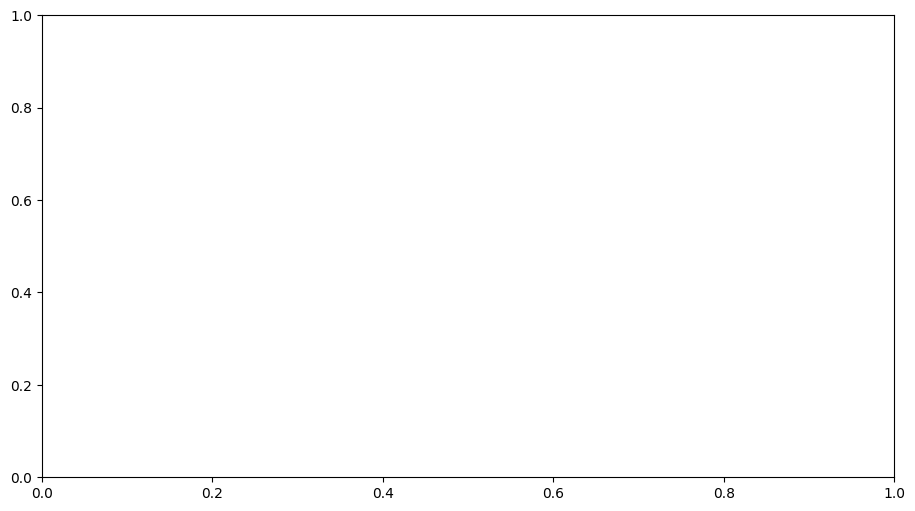

In [25]:
# Setup figure 
fig, axes = plt.subplots(1, 1, figsize=(11, 6), sharex=True)

shade_epochs(ax)

# Add legend 
ax.legend(bbox_to_anchor=(1.01, 1.0), loc='upper left', fontsize=8)

plt.show()

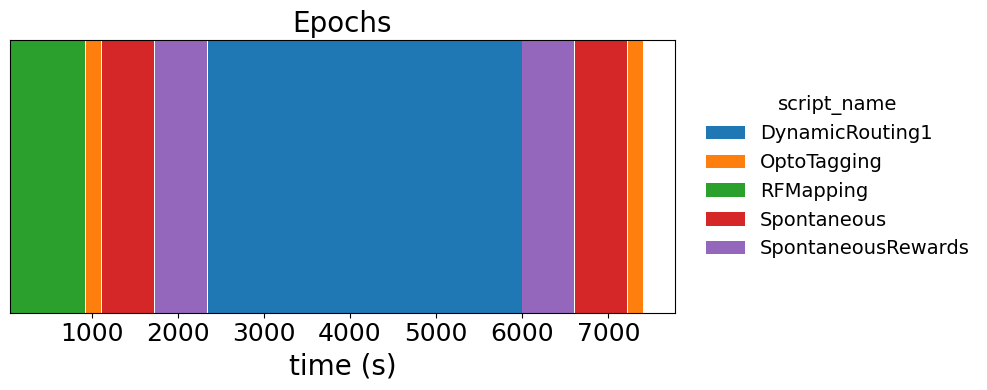

In [4]:
epochs_df = nwb.intervals["epochs"][:]

script_names = sorted(epochs_df["script_name"].unique())
script_colors = dict(zip(script_names, plt.get_cmap("tab10").colors))

fig, ax = plt.subplots(figsize=(10, 4))
for script_name, group in epochs_df.groupby("script_name"):
    ax.barh(
        y=np.zeros(len(group)),
        width=group["stop_time"] - group["start_time"],
        left=group["start_time"],
        height=1,
        color=script_colors[script_name],
        label=script_name,
    )
ax.set_yticks([])
ax.set_ylim(-0.5, 0.5)
ax.set_xlabel("time (s)", fontsize=20)
ax.tick_params(axis="x", labelsize=18)
ax.set_title("Epochs", fontsize=20)
ax.legend(
    title="script_name",
    fontsize=14,
    title_fontsize=14,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
)
plt.tight_layout()
plt.show()


Each epoch may be sub-divided into smaller intervals, e.g. trials or blocks of trials, in other tables: 

In [22]:
nwb.intervals["epochs"][:].set_index("script_name")["interval_names"]

script_name
RFMapping             [vis_rf_mapping_trials, aud_rf_mapping_trials]
OptoTagging                                     [optotagging_trials]
Spontaneous                                                       []
SpontaneousRewards                                                []
DynamicRouting1                                [trials, performance]
SpontaneousRewards                                                []
Spontaneous                                                       []
OptoTagging                                     [optotagging_trials]
Name: interval_names, dtype: object

---
## `DynamicRouting1` task trials

### `trials` table

- accessible via `nwb.intervals["trials"]` or `nwb.trials`

- **each row is one trial in the task**

- column types:
    - events (`*_time` suffix) 
        - `float`, seconds relative to start of session
    - boolean metadata (`is_*` prefix)
        - for easy filtering of rows
    - other metadata (`stim_name`, `rewarded_modality`, `block_index`) 
        - `int`, `str`
- column descriptions packaged in the NWB file:

| Column | Description |
| --- | --- |
| start_time | Start time of epoch (s) |
| stop_time | Stop time of epoch (s) |
| quiescent_start_time | Start of pre-stimulus interval in which the subject does not lick; only the last quiescent interval (which was not violated) is included |
| quiescent_stop_time | End of pre-stimulus interval in which the subject does not lick; not equal to `stim_start_time`, which factors in processing and stimulus device latency |
| stim_start_time | Onset of visual or auditory stimulus |
| stim_stop_time | Offset of visual or auditory stimulus |
| response_window_start_time | Start of interval in which the subject should lick if a GO trial, otherwise should not lick |
| response_window_stop_time | End of interval in which the subject should lick if a GO trial, otherwise should not lick |
| task_control_response_time | Time of first lick in trial according to the task control script; nan if no response registered |
| response_time | Time of first lick within the response window; nan if no lick occurred |
| reward_time | Delivery time of water reward, for contingent and non-contingent rewards |
| post_response_window_start_time | Start of null interval in which the subject awaits a new trial |
| post_response_window_stop_time | End of null interval |
| stim_name | The stimulus presented; corresponds to a unique stimulus definition, randomized over trials |
| grating_phase | Phase of the visual grating in cycles; 0 or 0.5 for visual stimuli; nan for auditory stimuli |
| block_index | 0-indexed block number, increments with each block |
| rewarded_modality | Name of the rewarded modality in each block; not an exact correspondence with values in `stim_name` |
| trial_index | 0-indexed trial number |
| trial_index_in_block | 0-indexed trial number within the block |
| repeat_index | Number of times the trial has already been presented in immediately preceding trials; nan for catch trials |
| is_response | The subject licked one or more times during the response window |
| is_correct | The subject acted correctly in the response window; includes correct reject for catch trials |
| is_incorrect | The subject acted incorrectly in the response window; includes false alarm for catch trials |
| is_hit | The subject responded in a GO trial |
| is_false_alarm | The subject responded in a NOGO trial; excludes catch trials |
| is_correct_reject | The subject did not respond in a NOGO trial; excludes catch trials |
| is_miss | The subject did not respond in a GO trial |
| is_go | Condition in which the subject should respond; target stim presented in rewarded block |
| is_nogo | Condition in which the subject should not respond; excludes catch trials |
| is_rewarded | The subject received a reward; includes non-contingent rewards |
| is_noncontingent_reward | The subject received a reward that did not depend on its response |
| is_contingent_reward | The subject received a reward for a correct response |
| is_reward_scheduled | A non-contingent reward was scheduled to occur regardless of whether it was delivered |
| is_instruction | Stimulus specifically chosen to inform the subject of a change in rewarded modality |
| is_aud_stim | An auditory stimulus was presented; excludes catch trials |
| is_vis_stim | A visual stimulus was presented; excludes catch trials |
| is_catch | No stimulus was presented |
| is_target | A stimulus was presented that the subject should respond to only in a specific block |
| is_aud_target | An auditory stimulus the subject should respond to only in a specific block |
| is_vis_target | A visual stimulus the subject should respond to only in a specific block |
| is_nontarget | A stimulus the subject should never respond to |
| is_aud_nontarget | An auditory stimulus the subject should never respond to |
| is_vis_nontarget | A visual stimulus the subject should never respond to |
| is_vis_rewarded | Visual target stimuli are rewarded |
| is_aud_rewarded | Auditory target stimuli are rewarded |
| is_block_switch | The first trial with a stimulus after a change in rewarded modality |
| is_repeat | The trial is a repetition of the previous trial due to a miss |
| is_opto | Optogenetic inactivation was applied during the trial |
| is_task_control_correct | The task control script interpreted the subject's response correctly; where False, `is_hit` or `is_miss` may be incorrect |

In [24]:
nwb.trials

,start_time,stop_time,quiescent_start_time,quiescent_stop_time,stim_start_time,stim_stop_time,response_window_start_time,response_window_stop_time,task_control_response_time,response_time,reward_time,post_response_window_start_time,post_response_window_stop_time,stim_name,grating_phase,block_index,rewarded_modality,trial_index,trial_index_in_block,repeat_index,is_response,is_correct,is_incorrect,is_hit,is_false_alarm,is_correct_reject,is_miss,is_go,is_nogo,is_rewarded,is_noncontingent_reward,is_contingent_reward,is_reward_scheduled,is_instruction,is_aud_stim,is_vis_stim,is_catch,is_target,is_aud_target,is_vis_target,is_nontarget,is_aud_nontarget,is_vis_nontarget,is_vis_rewarded,is_aud_rewarded,is_block_switch,is_repeat,is_opto,is_task_control_correct
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,2348.22379,2353.72868,2348.22379,2349.69168,2349.752705,2350.25312,2349.80842,2350.72585,2350.22542,2350.22190,2350.24210,2350.753525,2353.75605,vis1,0.0,0,vis,0,0.0,0.0,True,True,False,True,False,False,False,True,False,True,False,True,True,True,False,True,False,True,False,True,False,False,False,True,False,False,False,False,False
1,2355.06282,2360.56744,2355.06282,2356.53071,2356.591540,2357.09195,2356.64748,2357.56494,2356.98109,2356.97794,2356.99778,2357.592370,2360.59488,vis1,0.0,0,vis,1,1.0,0.0,True,True,False,True,False,False,False,True,False,True,False,True,True,True,False,True,False,True,False,True,False,False,False,True,False,False,False,False,False
2,2361.43482,2366.93945,2361.43482,2362.90275,2362.963540,2363.46395,2363.01948,2363.93691,2363.30308,2363.30304,2363.31977,2363.964370,2366.96689,vis1,0.5,0,vis,2,2.0,0.0,True,True,False,True,False,False,False,True,False,True,False,True,True,True,False,True,False,True,False,True,False,False,False,True,False,False,False,False,False
3,2367.13964,2372.66092,2367.13964,2368.60749,2368.668320,2369.16875,2368.72426,2369.64176,NaN,NaN,2369.64176,2369.669170,2372.68857,vis1,0.5,0,vis,3,3.0,0.0,False,False,True,False,False,False,True,True,False,True,True,False,True,True,False,True,False,True,False,True,False,False,False,True,False,False,False,False,False


Let's "discover" the block structure of the task by visualizing how the `rewarded_modality` changes across blocks:

In [37]:
# notes is this totally necessary? 

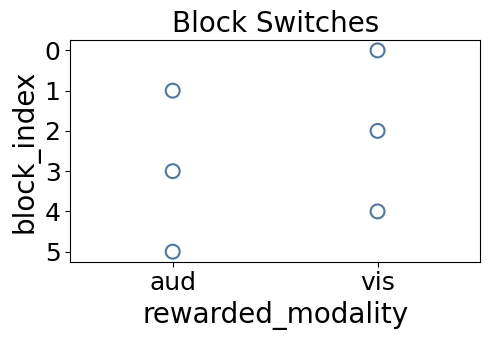

In [5]:
blocks_df = nwb.trials[:][["rewarded_modality", "block_index"]].drop_duplicates()

modalities = sorted(blocks_df["rewarded_modality"].unique())
block_indices = sorted(blocks_df["block_index"].unique())

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(
    [modalities.index(m) for m in blocks_df["rewarded_modality"]],
    blocks_df["block_index"],
    s=100,
    facecolors="none",
    edgecolors="#4c78a8",
    linewidths=1.5,
)
ax.set_xticks(range(len(modalities)), modalities, fontsize=18)
ax.set_xlim(-0.5, len(modalities) - 0.5)
ax.set_yticks(block_indices, [str(b) for b in block_indices], fontsize=18)
ax.invert_yaxis()           # block 0 at the top
ax.set_xlabel("rewarded_modality", fontsize=20)
ax.set_ylabel("block_index", fontsize=20)
ax.set_title("Block Switches", fontsize=20)
plt.tight_layout()
plt.show()


Similarly, let's check `stim_name` in the first few trials of each block:

In [ ]:
# notes - how do I change the presentation of the block identity? 

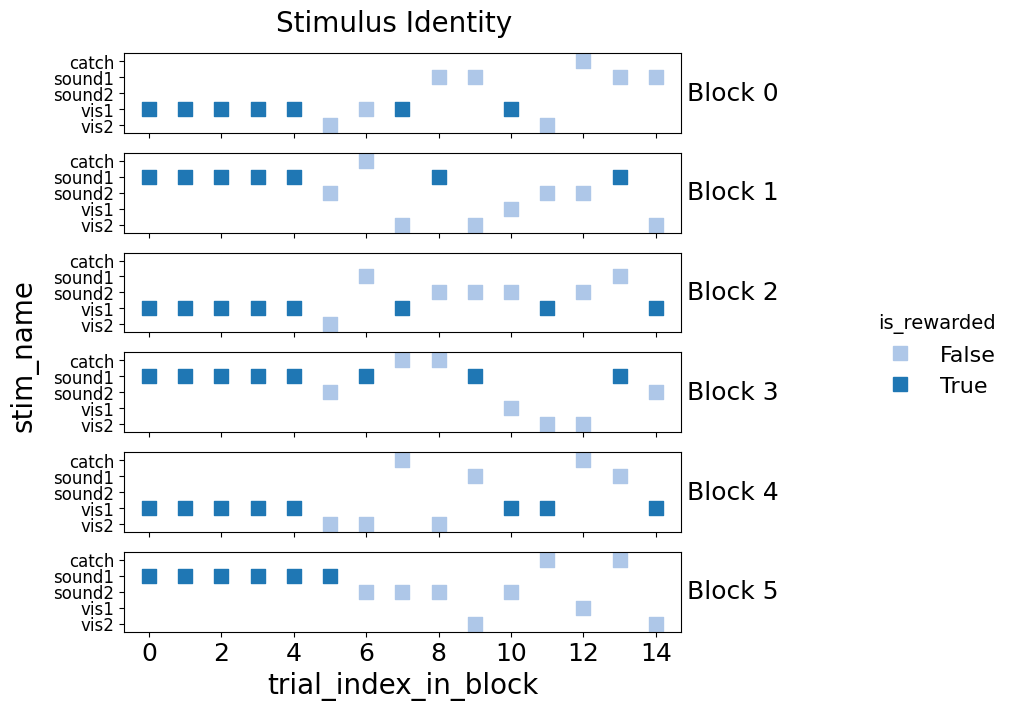

In [6]:
# stimulus identity in the first few trials of each block:
stim_df = nwb.trials[:].query("trial_index_in_block < 15")

blocks = sorted(stim_df["block_index"].unique())
stim_names = sorted(stim_df["stim_name"].unique())
stim_y = {name: i for i, name in enumerate(stim_names)}

fig, axes = plt.subplots(
    len(blocks), 1, figsize=(8, 1.2 * len(blocks)), sharex=True, sharey=True
)
for ax, block_index in zip(np.atleast_1d(axes), blocks):
    block_df = stim_df.query("block_index == @block_index")
    for is_rewarded, group in block_df.groupby("is_rewarded"):
        ax.scatter(
            group["trial_index_in_block"],
            [stim_y[name] for name in group["stim_name"]],
            marker="s",
            s=100,
            color=BOOL_COLORS[is_rewarded],
            label=str(is_rewarded),
        )
    ax.set_yticks(range(len(stim_names)), stim_names, fontsize=12)
    ax.set_ylim(len(stim_names) - 0.5, -0.5)   # first stim_name at the top
    ax.text(
        1.01, 0.5, f"Block {block_index}",
        transform=ax.transAxes, ha="left", va="center", fontsize=18,
    )

axes[-1].set_xlabel("trial_index_in_block", fontsize=20)
axes[-1].tick_params(axis="x", labelsize=18)
fig.supylabel("stim_name", fontsize=20)
fig.suptitle("Stimulus Identity", fontsize=20)

# one shared legend for the boolean color encoding
handles = [
    plt.Line2D([], [], marker="s", linestyle="", markersize=10, color=color, label=str(value))
    for value, color in BOOL_COLORS.items()
]
fig.legend(
    handles=handles,
    title="is_rewarded",
    fontsize=16,
    title_fontsize=14,
    loc="center left",
    bbox_to_anchor=(1.08, 0.5),
    frameon=False,
)
plt.tight_layout()
plt.show()


> 💡 
> 
> The first five trials in a block (instruction trials) have a non-contingent reward scheduled - if the mice fail to lick during the response window, they still receive a reward, unexpectedly. 
>
> We'll see later how quickly they update their behavior after the block switch.

### Timing within a trial

All times in the NWB file are relative to the start of the session (before the first epoch starts).

We might sometimes want to compute the response time relative to the stimulus onset in each trial.

<img src="images/trial-timing.png" style="max-width: 800px; height: auto;">

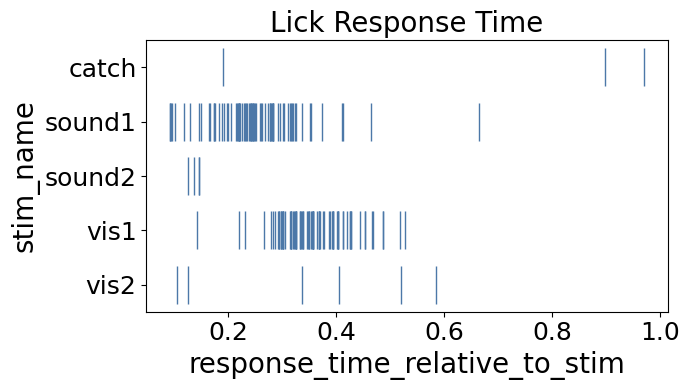

In [7]:
trials_df = nwb.intervals["trials"][:]

# add a new column:
trials_df["response_time_relative_to_stim"] = trials_df["response_time"] - trials_df["stim_start_time"]

stim_names = sorted(trials_df["stim_name"].unique())
response_times = [
    trials_df.loc[trials_df["stim_name"] == name, "response_time_relative_to_stim"].dropna().to_numpy()
    for name in stim_names
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.eventplot(
    response_times,
    lineoffsets=range(len(stim_names)),
    linelengths=0.7,
    linewidths=1,
    colors="#4c78a8",
)
ax.set_yticks(range(len(stim_names)), stim_names, fontsize=18)
ax.set_ylim(len(stim_names) - 0.5, -0.5)   # first stim_name at the top
ax.tick_params(axis="x", labelsize=18)
ax.set_xlabel("response_time_relative_to_stim", fontsize=20)
ax.set_ylabel("stim_name", fontsize=20)
ax.set_title("Lick Response Time", fontsize=20)
plt.tight_layout()
plt.show()


> 💡 
> 
> Response times to auditory stimuli are generally faster than to visual stimuli - phototransduction is slow compared to mechanotransduction.

---
## Task performance
- many Boolean columns in the trials table indicate behavioral outcomes:
    - `is_response`
    - `is_hit`
    - `is_miss`
    - `is_false_alarm`
    - `is_correct_reject`
    - ...

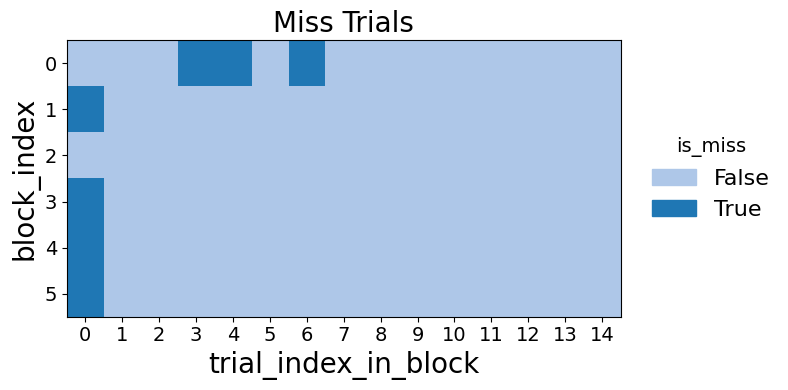

In [9]:
miss_grid = (
    nwb.intervals["trials"][:]
    .query("trial_index_in_block < 15")
    .pivot_table(index="block_index", columns="trial_index_in_block", values="is_miss", aggfunc="max")
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(
    miss_grid.to_numpy(dtype=float),
    cmap=ListedColormap([BOOL_COLORS[False], BOOL_COLORS[True]]),
    vmin=0,
    vmax=1,
    aspect="auto",
    interpolation="nearest",
)
ax.set_xticks(range(len(miss_grid.columns)), miss_grid.columns.astype(int), fontsize=14)
ax.set_yticks(range(len(miss_grid.index)), miss_grid.index.astype(int), fontsize=14)
ax.set_xlabel("trial_index_in_block", fontsize=20)
ax.set_ylabel("block_index", fontsize=20)
ax.set_title("Miss Trials", fontsize=20)
ax.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=color, label=str(value))
             for value, color in BOOL_COLORS.items()],
    title="is_miss",
    fontsize=16,
    title_fontsize=14,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
)
plt.tight_layout()
plt.show()


> 💡 
> 
> Once the mice learn the task, they typically only need one "miss" on the first trial of a block to update their behavior, and make very few misses in the rest of the block.

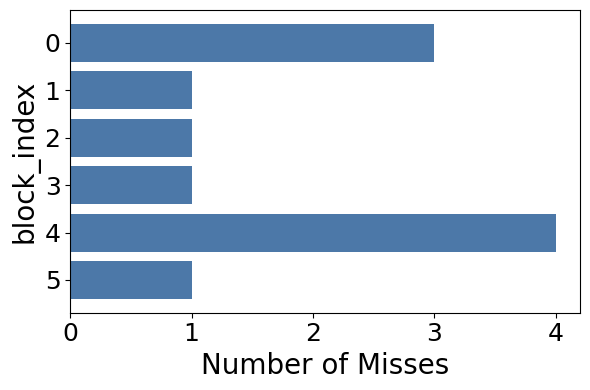

In [10]:
miss_counts = nwb.intervals["trials"][:].groupby("block_index")["is_miss"].sum()

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(
    range(len(miss_counts)),
    miss_counts.to_numpy(),
    height=0.8,
    color="#4c78a8",
)
ax.set_yticks(range(len(miss_counts)), miss_counts.index, fontsize=18)
ax.invert_yaxis()                                        # block 0 at the top
ax.set_xticks(np.arange(miss_counts.max() + 1))          # integer tick steps
ax.tick_params(axis="x", labelsize=18)
ax.set_xlabel("Number of Misses", fontsize=20)
ax.set_ylabel("block_index", fontsize=20)
plt.tight_layout()
plt.show()


The NWB file contains a pre-computed "performance" table with aggregated trial outcomes across each block. 

In [50]:
nwb.intervals["performance"]

,start_time,stop_time,block_index,n_trials,n_responses,n_hits,n_contingent_rewards,hit_rate,false_alarm_rate,catch_response_rate,rewarded_modality,is_first_block_aud,cross_modality_dprime,signed_cross_modality_dprime,vis_dprime,aud_dprime,vis_target_response_rate,vis_nontarget_response_rate,aud_target_response_rate,aud_nontarget_response_rate
id,,,,,,,,,,,,,,,,,,,,
0,2348.22379,2955.31550,0,86,22.0,20.0,20.0,0.869565,0.034483,4.400000,vis,False,2.376458,2.376458,3.084302,0.000000,0.944444,0.000000,0.105263,0.000000
1,2955.39894,3564.67599,1,73,29.0,21.0,21.0,0.954545,0.155556,4.833333,aud,False,2.121349,-2.121349,-0.332829,3.191708,0.333333,0.066667,1.000000,0.066667
2,3565.57660,4169.84933,2,84,27.0,22.0,22.0,0.956522,0.090909,4.500000,vis,False,2.345315,2.345315,3.649607,-0.048422,0.944444,0.000000,0.263158,0.000000
3,4171.60085,4779.42658,3,79,31.0,21.0,21.0,0.954545,0.187500,3.444444,aud,False,1.943969,-1.943969,-0.647083,3.224742,0.400000,0.117647,1.000000,0.062500


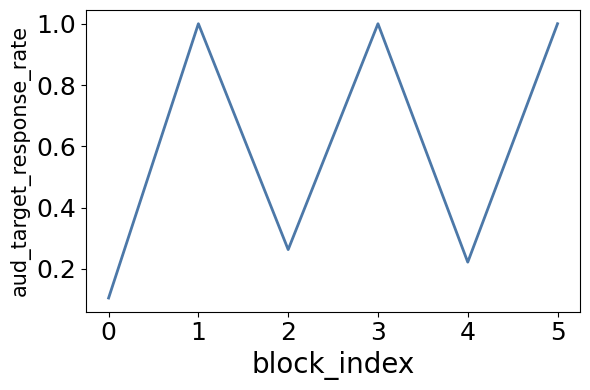

In [12]:
performance_df = nwb.intervals["performance"][:].sort_values("block_index")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(
    range(len(performance_df)),
    performance_df["aud_target_response_rate"],
    color="#4c78a8",
    lw=2,
)
ax.set_xticks(range(len(performance_df)), performance_df["block_index"], fontsize=18)
ax.tick_params(axis="y", labelsize=18)
ax.set_xlabel("block_index", fontsize=20)
ax.set_ylabel("aud_target_response_rate", fontsize=15)
plt.tight_layout()
plt.show()


---
# Neural data

### `units` table
- **each row is one recorded (putative) neuron from spike-sorting**

- metadata about each unit

- list-like `spike_times` and `spike_amplitudes` columns

- array-like `waveform_mean` and `waveform_sd` columns, which are be very large compared to the scalar metadata (excluded from these NWB files)

| Column | Description |
| --- | --- |
| activity_drift | Measure of drift in unit activity over the session |
| amplitude | Amplitude (µV) of the average spike waveform |
| amplitude_cutoff | Estimated fraction of spikes missing from this unit (default threshold = 0.1) |
| amplitude_cv_median | Median coefficient of variation of spike amplitudes |
| amplitude_cv_range | Range of coefficient of variation of spike amplitudes |
| amplitude_median | Median spike amplitude (µV) |
| ccf_ap | Anterior-posterior coordinate in Allen CCF atlas (µm) |
| ccf_dv | Dorsal-ventral coordinate in Allen CCF atlas (µm) |
| ccf_ml | Medial-lateral coordinate in Allen CCF atlas (µm) |
| cluster_id | Identifier for this unit assigned by the spike sorting algorithm (unique within each probe) |
| d_prime | Measure of how separable this unit's waveforms are from its neighbors' |
| decoder_label | Predicted cell type label from decoder |
| decoder_probability | Confidence of decoder cell type prediction [0-1] |
| default_qc | Whether the unit passes default quality control criteria |
| device_name | Name of the recording device |
| drift_mad | Median absolute deviation of unit drift |
| drift_ptp | Peak-to-peak amplitude of unit drift (µm) |
| drift_std | Standard deviation of unit drift |
| electrode_group_name | Name of the electrode group the unit was recorded from |
| exp_decay | Exponential decay of the autocorrelogram |
| firing_range | Range of firing rates across the session |
| firing_rate | Mean spike rate across the whole session (Hz) |
| half_width | Half-width of the mean spike waveform (s) |
| is_not_drift | Boolean indicating unit is not classified as a drift artifact |
| is_qc_pass | Boolean indicating unit passes quality control |
| isi_violations_count | Number of inter-spike interval violations (<1.5 ms) |
| isi_violations_ratio | Measure of unit contamination from refractory period violations (default threshold = 0.5) |
| isolation_distance | Distance to nearest cluster in Mahalanobis space; higher is better |
| l_ratio | Measure of how separable this unit's waveforms are from its neighbors'; lower is better |
| location | brain structure (acronym) |
| nn_hit_rate | Fraction of spikes with nearest neighbor from same cluster |
| nn_miss_rate | Measure of fraction of spikes missing from this unit |
| num_negative_peaks | Number of negative peaks in the mean spike waveform |
| num_positive_peaks | Number of positive peaks in the mean spike waveform |
| num_spikes | Total number of spikes detected for the unit |
| peak_channel | Channel index with the largest amplitude waveform |
| peak_electrode | Electrode index with the largest amplitude spike waveform |
| peak_to_valley | Time (s) between waveform peak and trough |
| peak_trough_ratio | Peak-to-trough ratio of the average spike waveform |
| presence_ratio | Fraction of the session over which this unit had spikes detected (default threshold = 0.9) |
| recovery_slope | Slope of the waveform between the trough and the peak (V/s) |
| repolarization_slope | Slope of the waveform back to 0 after the peak (V/s) |
| rp_contamination | Estimated contamination from refractory period violations |
| rp_violations | Number of refractory period violations |
| silhouette | Measure of unit contamination based on cluster separation |
| sliding_rp_violation | Sliding refractory period violation metric |
| snr | Ratio of waveform amplitude relative to background noise on the peak channel |
| spike_amplitudes | Array of individual spike amplitudes (µV) |
| spread | Distance the waveform extends above and below the peak channel (µm) |
| structure | Brain structure acronym where the unit was recorded |
| sync_spike_2 | Synchrony of unit spikes within 2 ms windows |
| sync_spike_4 | Synchrony of unit spikes within 4 ms windows |
| sync_spike_8 | Synchrony of unit spikes within 8 ms windows |
| unit_id | Unique UUID identifier for the unit |
| velocity_above | Speed of waveform propagation above the peak channel (V/s) |
| velocity_below | Speed of waveform propagation below the peak channel (V/s) |
| spike_times | Timestamps (s) of each detected spike for the unit |
| obs_intervals | Time intervals during which the unit was observed/recorded |
| electrode_group | The electrode group that each spike unit came from |


Let's load the units dataframe without the unnecessary columns:


In [13]:
units_df = nwb.units.to_dataframe(exclude={"spike_amplitudes", "waveform_mean", "waveform_sd"})

with pd.option_context('display.max_rows', 5, 'display.max_columns', None, 'display.max_colwidth', 100):
    display(units_df)

UnsafeDecodeError: Pickle.decode is disabled because unpickling data can execute arbitrary code. If you trust the source of this data, enable it by setting numcodecs.pickles.ALLOW_UNSAFE_PICKLE_DECODE = True, or by setting the environment variable NUMCODECS_ALLOW_UNSAFE_PICKLE_DECODE=1 before importing numcodecs.

### Brain areas recorded

> 💡 
> 
> probe insertion tracks in the subject's brain are manually annotated and warped to a reference brain
>
> each recording site can be expressed in a common coordinate system (Allen CCF) across subjects - more info: https://allenswdb.github.io/background/CCF.html

Let's visualize the location of all the recording sites in this dataset:

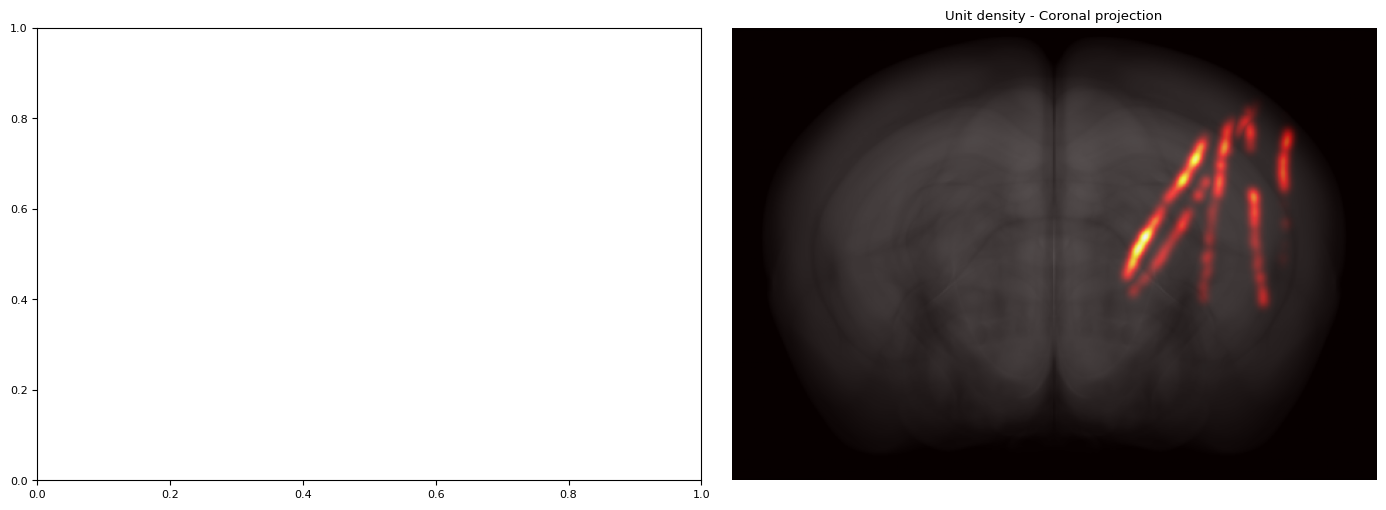

In [ ]:
import pynwb_utils    # <-- local utility function with plotting functions

# using the brainglobe data asset + package
pynwb_utils.plot_ccf_density_heatmap(units_df)
plt.show()


# is something not working correctly with the pynwb utils? how come only one side is showing up? 

Each recording site below is colored by its brain region (see legend):


In [ ]:
pynwb_utils.plot_ccf_coordinates(units_df)
plt.show()


> 💡 
> 
> The physical probes are straight, but appear wobbly due to the warping into the CCF. 

In [58]:
pynwb_utils.get_area_summary_df(units_df)

# rewrite this and/or order by n units 

,description,n units,n passing qc
structure (acronym),,,
AUDp,Primary auditory area,130,36
AUDpo,Posterior auditory area,193,66
CA1,Field CA1,103,16
CA3,Field CA3,54,12
CP,Caudoputamen,1157,224
DG,Dentate gyrus,34,1
FF,Fields of Forel,9,1
LGd,Dorsal part of the lateral geniculate complex,109,22
MB,Midbrain,37,5


Note: 
- `structure` is the coarse brain area label in the NWB files
- `location` is the more specific label and coresponds to `acronym` in the Allen CCF ontology.

## Single-unit exploration
### Metadata for a single unit

In [59]:
UNIT_ID = "742903_2024-10-23_C-11"

units_df.query("unit_id == @UNIT_ID")[
    ["structure", "location", "electrode_group_name", "is_qc_pass", "activity_drift"]
]

,structure,location,electrode_group_name,is_qc_pass,activity_drift
id,,,,,
1258,AUDp,AUDp6b,probeC,True,0.073717


`is_qc_pass` allows quick filtering for units whose activity is stable over the task, and that do not appear to be noise:
- `activity_drift < 0.1`
- `amplitude_cutoff <= 0.1`
-  `presence_ratio > 0.7`
- `decoder_label != "noise"`

### Windowed spike times
<img src="images/spikes.png" width="800">

In [ ]:
spike_times = units_df.query("unit_id == @UNIT_ID")["spike_times"].iloc[0]
truncated_spike_times = pd.DataFrame({'spike_times': spike_times[:100]})

# this isn't really getting spikes in the trial window, but just getting the first 100 spikes... 

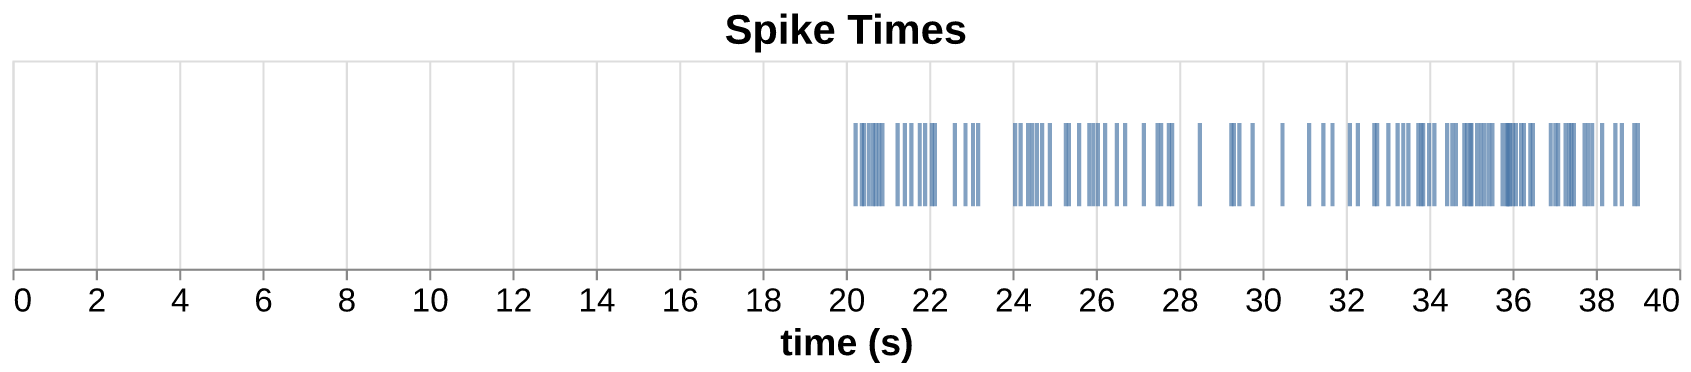

In [ ]:
fig, ax = plt.subplots(figsize=(10, 1.8))
ax.eventplot(
    truncated_spike_times["spike_times"].to_numpy(),
    lineoffsets=0,
    linelengths=1,
    linewidths=2,
    colors="#4c78a8",
)
ax.set_yticks([])
ax.set_ylim(-0.5, 0.5)
ax.set_xlabel("time (s)", fontsize=18)
ax.tick_params(axis="x", labelsize=16)
ax.set_title("Spike Times", fontsize=20)
plt.tight_layout()
plt.show()


### Stimulus-aligned response (PSTH)

In [72]:
query = "is_aud_stim"

# time window around stimulus onset
xmin = -1.5 # seconds
xmax = 2.0  # seconds
bin_size = 0.001

# count spikes in each bin, summed across all trials
n_bins = int(round((xmax - xmin) / bin_size))
bins = xmin + np.arange(n_bins + 1) * bin_size
counts = np.zeros(n_bins)
for stim_start in trials_df.query(query)["stim_start_time"]:
    counts += np.histogram(spike_times - stim_start, bins=bins)[0]

smooth_ms = 100
smooth_bins = int(round((smooth_ms / 1000) / bin_size))
kernel = np.ones(smooth_bins) / smooth_bins
rate_hz = counts / len(trials_df.query(query)) / bin_size
psth_hz = np.convolve(rate_hz, kernel, mode="valid")

# center time of each valid smoothing window
bin_centers = bins[:-1] + bin_size / 2
t = bin_centers[:len(psth_hz)] + (smooth_bins - 1) * bin_size / 2

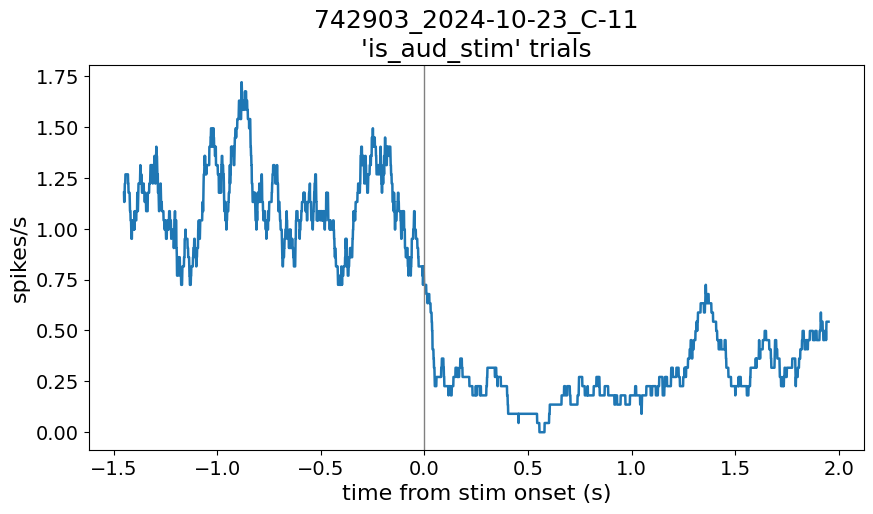

In [73]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t, psth_hz, lw=1.8)
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("time from stim onset (s)", fontsize=16)
ax.set_ylabel("spikes/s", fontsize=16)
ax.set_title(f"{UNIT_ID}\n{query!r} trials", fontsize=18)
ax.tick_params(labelsize=14)
plt.show()

In [74]:
# plt.plot(t, psth_hz, lw=1.2)
# plt.axvline(0, color="gray", lw=0.8)
# plt.xlabel("time from stim onset (s)")
# plt.ylabel("spikes/s")
# plt.gcf().set_size_inches(3, 3)
# plt.title(f"{UNIT_ID}\n{query!r} trials")
# plt.show()


# # now we're using matplotlib, why??? 

> 💡 
> 
> This unit is strongly suppressed by auditory stimuli - but we haven't looked at targets vs non-targets yet, or differences across blocks.
>
> How does it respond to visual stimuli?

## Activity by stimulus and block

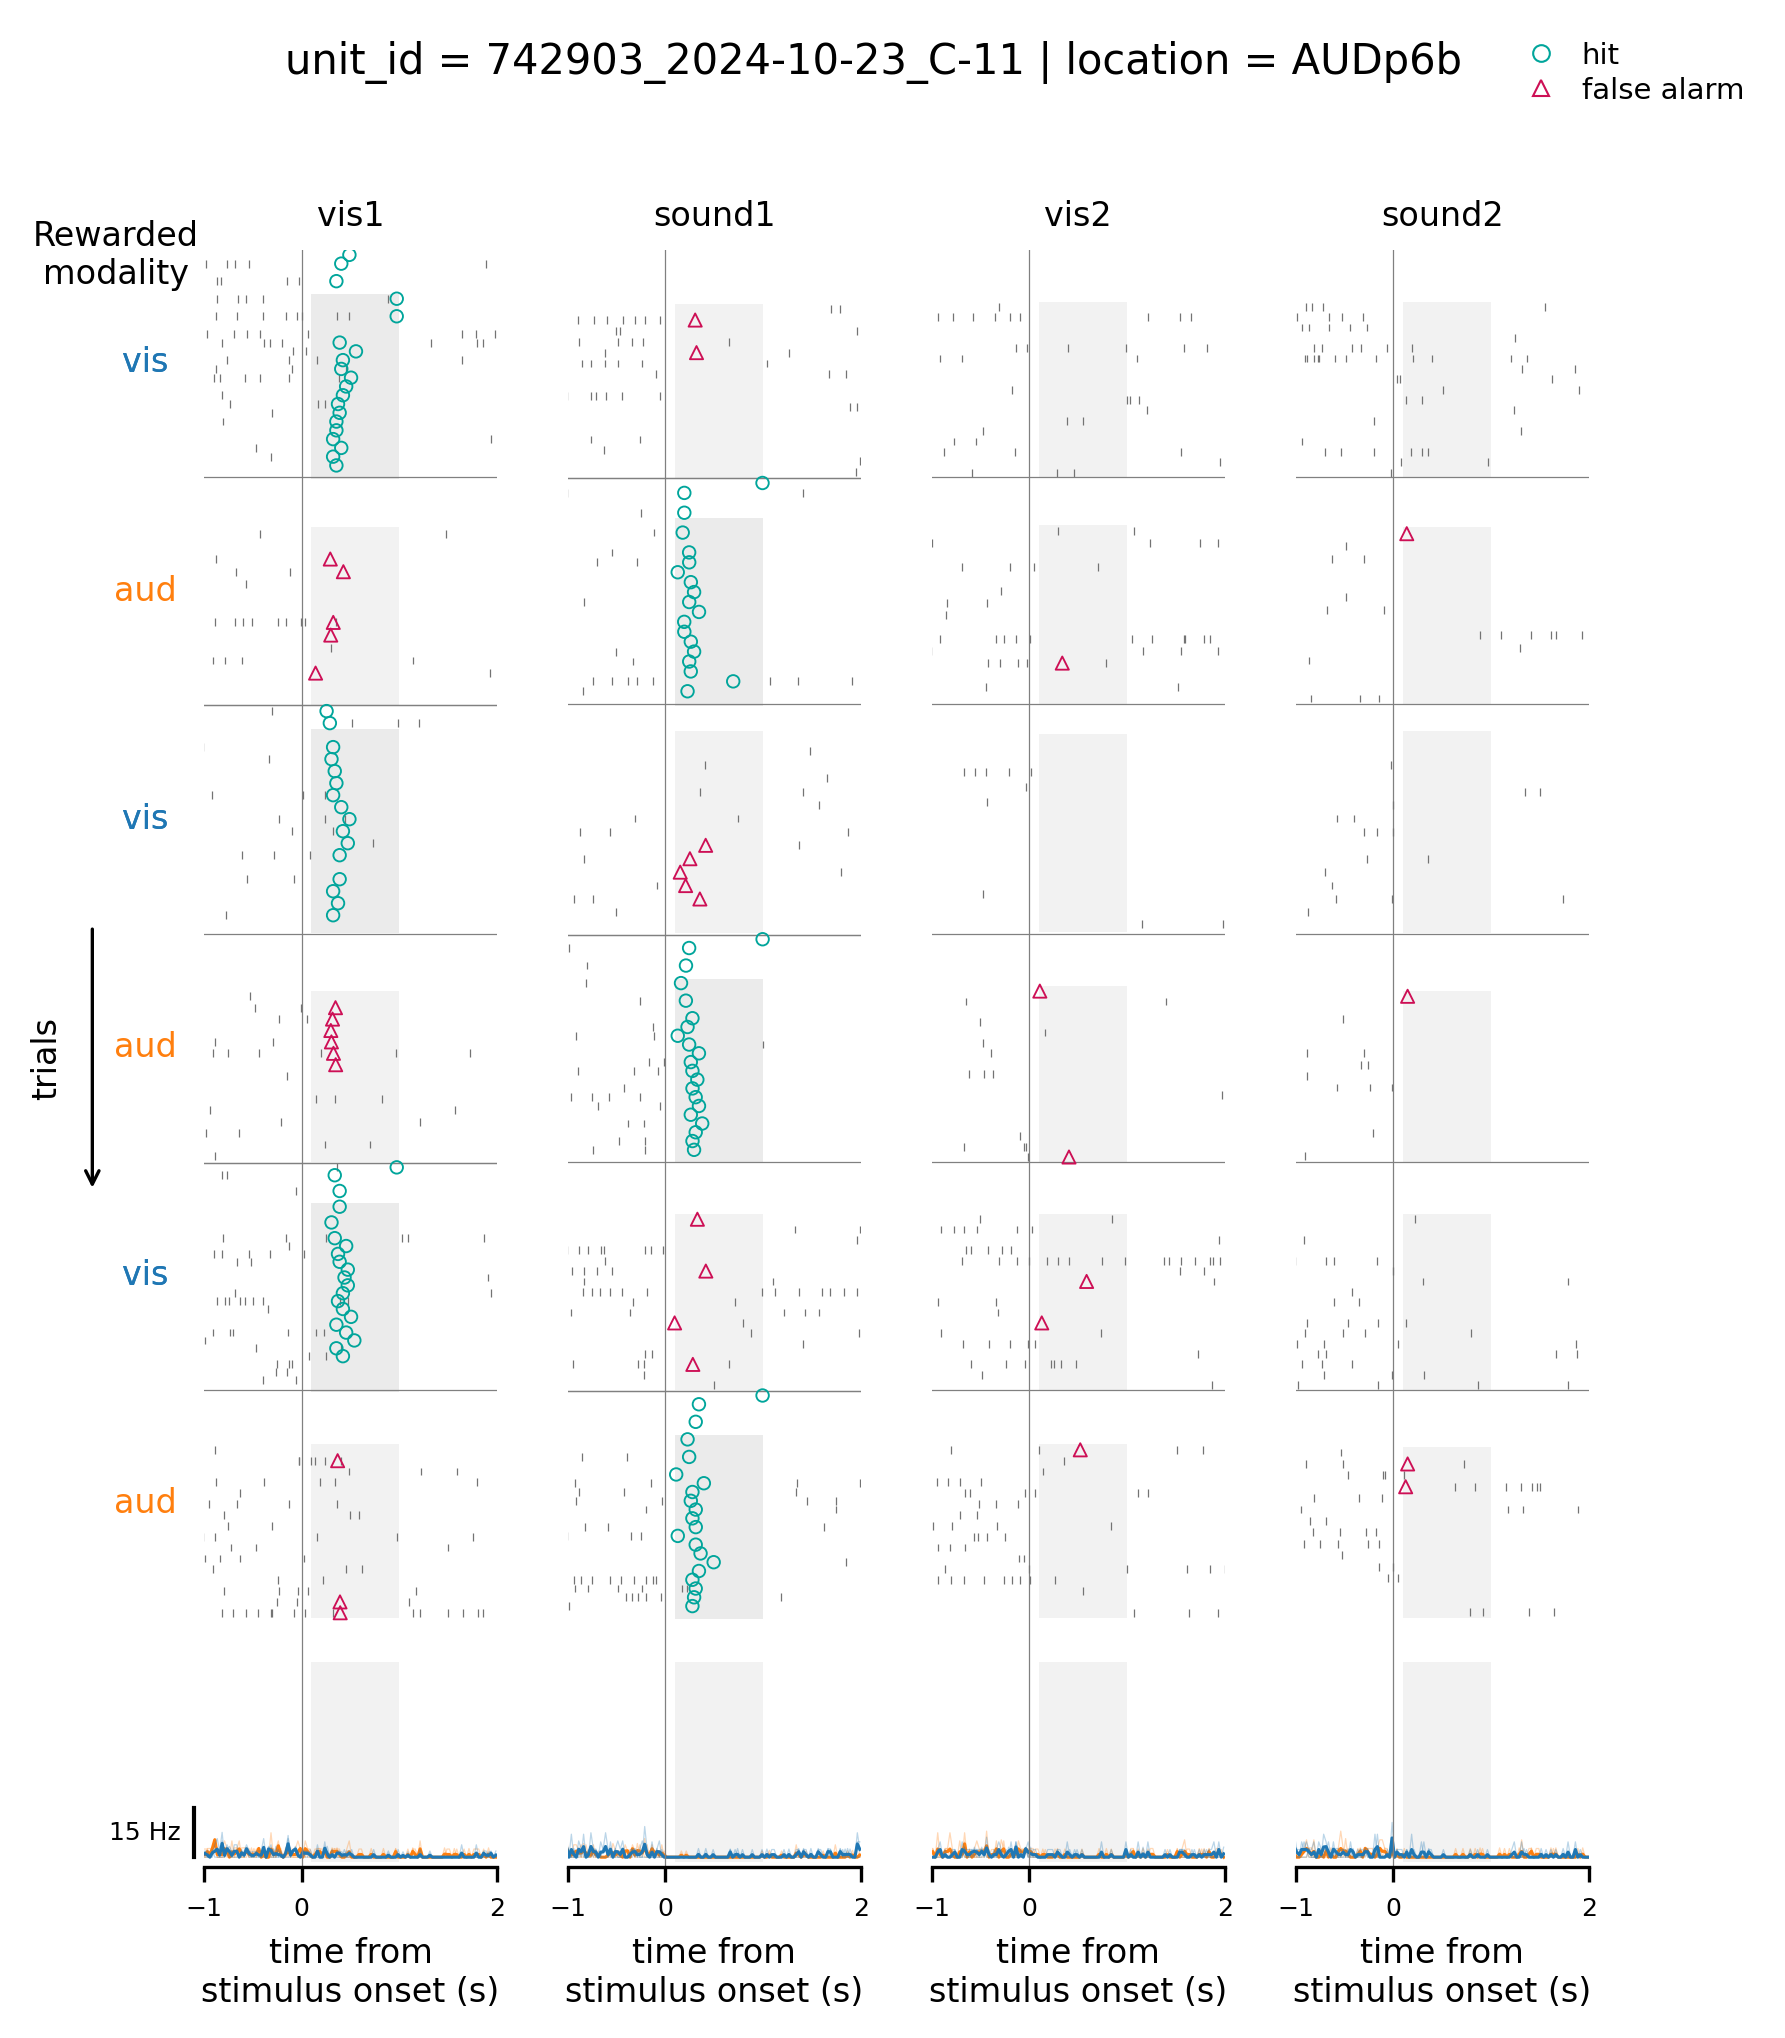

In [77]:
# to do - not sure what's going on here... 

unit_id = UNIT_ID

# or use a custom units filter and get a random unit:
query = "is_qc_pass and structure == 'MOp' and firing_rate > 5"
random_unit_id = units_df.query(query).sample(1)["unit_id"].iloc[0] 
# unit_id = random_unit_id

fig = pynwb_utils.plot_unit_raster_psth(
    unit_id=unit_id,
    nwb_or_units_df=units_df,
    trials_df=nwb.trials[:],
    stim_names=("vis1", "sound1", "vis2", "sound2"),
    max_psth_spike_rate=60,
)
plt.show()


# to do - adjust the plotting style and this is too much to show 
# maybe show just one plot first and then show the rest. 

> 💡 
> # need to find a different example and change this text 

> This unit's activity is more-strongly suppressed by the target stimuli. Activity is also higher during the quiescent, pre-stimulus periods of VIS rewarded blocks.
>
> Are these common features of units in ORB?
> What about other brain areas?


---
# Continuous behavioral data

## Accessing timeseries containers


In [78]:
running_speed = nwb.processing["behavior"]["running_speed"]
display(running_speed.timestamps, running_speed.data)

<zarr.core.Array '/processing/behavior/running_speed/timestamps' (431581,) float64 read-only>

<zarr.core.Array '/processing/behavior/running_speed/data' (431581,) float64 read-only>

In [79]:
sampling_rate_hz = 1 / np.median(np.diff(running_speed.timestamps[:1000]))
sampling_rate_hz 

np.float64(59.95203836930126)

In [82]:
n_samples_to_plot = int(sampling_rate_hz * 60 * 4)
start_sample = int(sampling_rate_hz * 60 * 70)  # at 70min the task is ongoing

t = running_speed.timestamps[start_sample:start_sample + n_samples_to_plot]
y = running_speed.data[start_sample:start_sample + n_samples_to_plot]

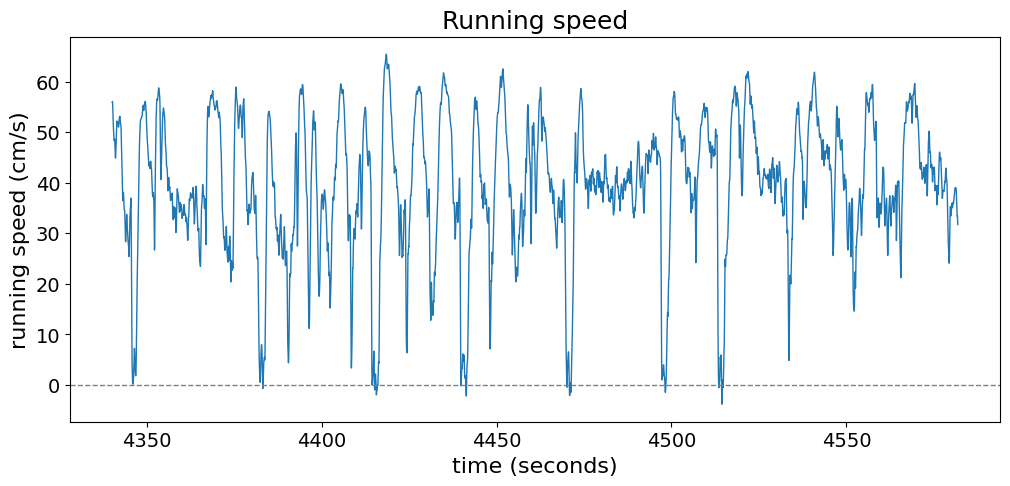

In [83]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t, y, lw=1)
ax.axhline(0, color="gray", linestyle="dashed", lw=1)
ax.set_xlabel(f"time ({running_speed.timestamps_unit})", fontsize=16)
ax.set_ylabel(f"running speed ({running_speed.unit})", fontsize=16)
ax.set_title("Running speed", fontsize=18)
ax.tick_params(labelsize=14)
plt.show()

## Running speed by outcome and block

In [84]:
running_time_grid = np.arange(-1.5, 2, 0.05)

# filter trials to hits and correct rejects, excluding instructions and catch
running_trials = trials_df[
    (trials_df["is_vis_target"] | trials_df["is_aud_target"]) &
    (trials_df["is_hit"] | trials_df["is_correct_reject"])
].copy()
running_trials["outcome"] = np.where(running_trials["is_hit"], "hit", "correct reject")

# load running speed as numpy arrays
rs_times = np.array(running_speed.timestamps)
rs_data = np.array(running_speed.data)

# align running speed to each trial's stimulus onset
aligned_rows = []
for _, trial in running_trials.iterrows():
    sample_times = trial["stim_start_time"] + running_time_grid
    if sample_times[0] < rs_times[0] or sample_times[-1] > rs_times[-1]:
        continue
    aligned_rows.append({
        "rewarded_modality": trial["rewarded_modality"],
        "outcome": trial["outcome"],
        "running_speed": np.interp(sample_times, rs_times, rs_data),
    })

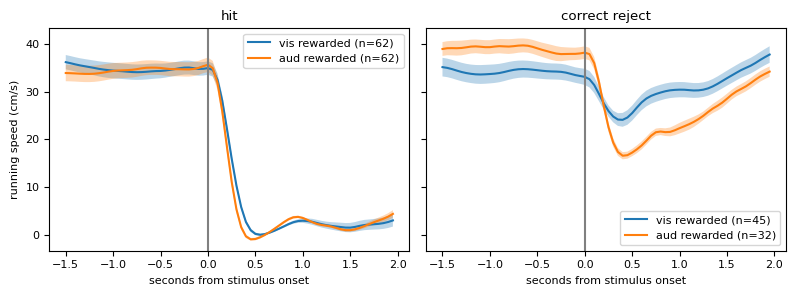

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True, sharey=True)
for col_idx, outcome in enumerate(["hit", "correct reject"]):
    ax = axes[col_idx]
    for modality in ["vis", "aud"]:
        traces = np.vstack([r["running_speed"] for r in aligned_rows
                            if r["outcome"] == outcome and r["rewarded_modality"] == modality])
        mean = traces.mean(axis=0)
        sem = traces.std(axis=0, ddof=1) / np.sqrt(len(traces))
        ax.plot(running_time_grid, mean, label=f"{modality} rewarded (n={len(traces)})")
        ax.fill_between(running_time_grid, mean - sem, mean + sem, alpha=0.3)
    ax.axvline(0, color="gray")
    ax.set_title(outcome)
    ax.set_xlabel("seconds from stimulus onset")
    if col_idx == 0:
        ax.set_ylabel(f"running speed ({running_speed.unit})")
    ax.legend()
plt.tight_layout()
plt.show()

> 💡 
> 
> Running speed appears to be higher during AUD rewarded blocks. Is this consistent across subjects?

## Facial features from `lightning pose (lp)` 
- markerless pose estimation using deep learning


<img src="images/nose_cam.png" style="max-width: 600px; height: auto;">

In [86]:
nwb.processing["behavior"]["lp_side_camera"]

,ear_base_l_likelihood,ear_base_l_pca_error,ear_base_l_temporal_norm,ear_base_l_x,ear_base_l_y,ear_tip_l_likelihood,ear_tip_l_pca_error,ear_tip_l_temporal_norm,ear_tip_l_x,ear_tip_l_y,eye_bottom_l_likelihood,eye_bottom_l_pca_error,eye_bottom_l_temporal_norm,eye_bottom_l_x,eye_bottom_l_y,eye_top_l_likelihood,eye_top_l_pca_error,eye_top_l_temporal_norm,eye_top_l_x,eye_top_l_y,jaw_likelihood,jaw_pca_error,jaw_temporal_norm,jaw_x,jaw_y,nose_tip_likelihood,nose_tip_pca_error,nose_tip_temporal_norm,nose_tip_x,nose_tip_y,nostril_l_likelihood,nostril_l_pca_error,nostril_l_temporal_norm,nostril_l_x,nostril_l_y,tongue_base_l_likelihood,tongue_base_l_pca_error,tongue_base_l_temporal_norm,tongue_base_l_x,tongue_base_l_y,tongue_tip_likelihood,tongue_tip_pca_error,tongue_tip_temporal_norm,tongue_tip_x,tongue_tip_y,whisker_pad_l_side_likelihood,whisker_pad_l_side_pca_error,whisker_pad_l_side_temporal_norm,whisker_pad_l_side_x,whisker_pad_l_side_y,whisker_pad_l_top_likelihood,whisker_pad_l_top_pca_error,whisker_pad_l_top_temporal_norm,whisker_pad_l_top_x,whisker_pad_l_top_y,timestamps
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0.000168,113.634712,NaN,334.101990,246.351898,0.000165,80.201294,NaN,320.449493,243.567368,0.999813,253.561401,NaN,650.118896,486.369629,0.000015,170.079758,NaN,614.413025,460.942322,0.000160,NaN,NaN,336.458282,242.234177,0.000162,191.657166,NaN,340.869415,239.859329,0.000159,205.941864,NaN,355.194000,239.742935,0.000164,50.302727,NaN,327.444672,241.231842,0.000164,39.052067,NaN,326.889801,241.579758,0.002585,110.122940,NaN,648.806458,153.859589,0.000008,184.418045,NaN,633.302002,423.779114,NaN
1,0.984427,14.296690,145.905579,217.447479,158.715347,0.980177,14.597552,134.858231,229.072510,144.385757,0.995436,21.102558,585.311157,168.748886,153.395035,0.993100,11.945509,548.778198,165.582031,145.176193,0.999667,NaN,178.109421,167.292831,186.502518,0.999443,21.899128,215.913055,134.065445,177.806427,0.997810,14.518596,224.312042,139.367630,178.629333,0.000086,24.960115,82.100899,248.884720,217.380386,0.000117,33.456520,53.982174,274.467041,228.698410,0.999693,40.969143,493.497955,155.640610,171.961975,0.999947,9.656710,547.361511,150.896622,165.148758,13.95943
2,0.960362,12.317565,2.119277,219.462357,158.058380,0.959865,11.835076,1.669532,227.557404,143.684479,0.996968,17.901455,0.287618,168.604156,153.146484,0.996046,10.422182,0.263124,165.383209,145.003845,0.998784,NaN,1.030870,168.043793,185.796295,0.999598,18.919535,0.342078,133.959167,177.481277,0.998625,12.092987,0.280835,139.358017,178.348663,0.000075,21.046926,12.352938,237.260605,213.200073,0.000085,22.664263,30.616556,245.238342,219.584869,0.999932,33.715542,0.322914,155.684174,171.642014,0.999961,8.430417,0.269866,150.899445,164.878906,13.97609
3,0.997458,11.497682,1.081304,219.052185,157.057892,0.975741,9.145262,2.072351,226.530319,141.884552,0.997098,15.920124,0.546781,168.495712,152.610565,0.982847,9.769206,0.415632,165.281097,144.600952,0.997884,NaN,0.308183,168.278748,185.596863,0.998123,16.699823,0.185413,133.960342,177.295868,0.998307,10.370335,0.230795,139.451675,178.137726,0.000074,22.619188,2.384256,235.158966,212.074112,0.000065,11.030844,24.257204,222.243744,211.860855,0.999984,29.260208,0.457973,155.344589,171.334732,0.999149,8.042360,0.373886,150.642258,164.607529,13.99276


> 💡 
> 
> each keypoint has a "likelihood" score - check its distribution and filter out low-confidence detections

In [88]:
keypoint = "ear_base_l_y"
likelihood_keypoint = f"{keypoint[:-2]}_likelihood"

# filter trials (same criteria as running speed)
pose_trials = trials_df[
    (trials_df["is_vis_target"] | trials_df["is_aud_target"]) &
    (trials_df["is_hit"] | trials_df["is_correct_reject"])
].copy()
pose_trials["outcome"] = np.where(pose_trials["is_hit"], "hit", "correct reject")

# extract keypoint data only (exclude other columns to save memory and speed up loading)
exclude_cols = set(nwb.processing["behavior"]["lp_side_camera"].colnames) - {"timestamps", keypoint, likelihood_keypoint}
lp_df = (
    nwb.processing["behavior"]["lp_side_camera"]
    .to_dataframe(exclude=exclude_cols)
    .query(f"{likelihood_keypoint} > 0.9") # filter out low-confidence keypoint estimates
)

pose_times = lp_df["timestamps"].to_numpy()
pose_values = lp_df[keypoint].to_numpy()

# align keypoint to each trial's stimulus onset
xmin = -1.5
pose_time_grid = np.arange(xmin, 2.0, 0.05)
aligned_rows = []
for _, trial in pose_trials.iterrows():
    sample_times = trial["stim_start_time"] + pose_time_grid
    if sample_times[0] < pose_times[0] or sample_times[-1] > pose_times[-1]:
        continue
    values = np.interp(sample_times, pose_times, pose_values)
    aligned_rows.append({
        "rewarded_modality": trial["rewarded_modality"],
        "outcome": trial["outcome"],
        "values": values,
    })

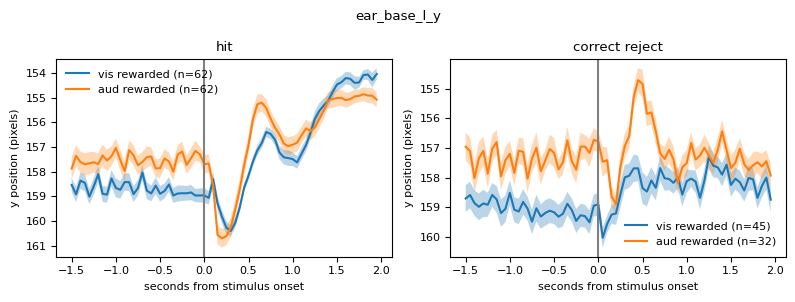

In [89]:
# plot keypoint by outcome
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True)
for col_idx, outcome in enumerate(["hit", "correct reject"]):
    ax = axes[col_idx]
    for modality in ["vis", "aud"]:
        traces = np.vstack([r["values"] for r in aligned_rows
                            if r["outcome"] == outcome and r["rewarded_modality"] == modality])
        mean = traces.mean(axis=0)
        sem = traces.std(axis=0, ddof=1) / np.sqrt(len(traces))
        ax.plot(pose_time_grid, mean, label=f"{modality} rewarded (n={len(traces)})")
        ax.fill_between(pose_time_grid, mean - sem, mean + sem, alpha=0.3)
    ax.axvline(0, color="gray")
    ax.set_title(outcome)
    ax.set_xlabel("seconds from stimulus onset")
    ax.set_ylabel("y position (pixels)")
    ax.invert_yaxis() # in images, (0, 0) is top-left corner
    ax.legend(frameon=False)

plt.suptitle(keypoint)
plt.tight_layout()
plt.show()

> 💡 
> 
> The ear is slightly higher during AUD rewarded blocks, even before the stimulus onset!
>
> Do any other keypoints show differences across blocks or trial outcomes?